# Teaching NanoGPT to Do Math with DPO

SC3000/CZ3005 Assignment 1

**Team and contributions:** *(to fill in before submission: team name, members, and what each member did. The manual asks for this when a team has more than one member.)*

## Overview

The model is a small character-level NanoGPT (8.8M parameters) pretrained on question-answer chat data. Before fine-tuning, it answers arithmetic questions with "Sorry, I don't know." We fine-tune it with DPO (Direct Preference Optimization). For each question the training data holds a preferred reply (the *positive*, a correct answer with its working) and a rejected reply (the *negative*, the pretrained model's own refusal). The loss makes the positive more likely than the negative.

| Task | Where | Result |
|---|---|---|
| Task 1: build positive-negative pairs | the "Task 1" section after Step 4 | `pos_neg_pairs.json`, 100,202 pairs |
| Task 2: fine-tune with DPO | Steps 5–7 | `dpo.pt` |
| Task 3: test the fine-tuned model | Step 8 | answers to the template's test set, accuracy on our 600 test questions |
| Task 4: explanation and analysis | the text cells | |

**How to run.** Start Jupyter from the `dpo/` folder, because the code uses relative paths such as `../sft/gpt.pt` and `../model.py`. Then run the cells from top to bottom. On an Apple M2 Pro laptop GPU (MPS), Task 1 takes about 190 minutes and training about 114 minutes. A CUDA GPU is faster.

**To test the submitted `dpo.pt` only** (without rebuilding the data or retraining): run Steps 1–4 and the first Task 1 cell, skip the second Task 1 cell (the one that calls `main`) and Steps 5–7, then run Step 8.

**Changes to the provided template** (each one is explained where it happens):
- Step 1 installs packages with `%pip` instead of `!pip`.
- Step 2 also uses Apple's GPU (`mps`), drops the `CUDA_VISIBLE_DEVICES = "1"` line, sets `max_length = 80`, and uses learning rate `1e-3` and 12 epochs instead of `1e-4` and 5.
- Step 7 checks the accuracy on the test questions after every epoch.
- Step 8 uses `.to(device)` instead of `.cuda()`, so it also runs without an NVIDIA GPU.

### Step 1: Install necessary packages

`%pip` installs into the environment of the running kernel. `!pip` runs whichever `pip` comes first on the shell's PATH, which can belong to a different Python. Only `torch`, `numpy`, `matplotlib` and `tqdm` are used below; the other packages are kept from the template.

In [1]:
%pip install matplotlib
%pip install torch numpy transformers datasets tiktoken wandb tqdm

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Step 2: Package imports and configuration

Changes from the template:
- **Device.** The template only checks for CUDA. We also use Apple's GPU (`mps`) when there is one, and fall back to the CPU otherwise.
- **`CUDA_VISIBLE_DEVICES = "1"` removed.** That line hides every GPU except the second one. On a machine with a single GPU, PyTorch would then see no GPU at all and silently train on the CPU.
- **`max_length = 80` instead of 64.** The longest positives, such as `x*100=10000,x=? The answer is 100 because 10000/100 equals to 100.`, are 70 characters long with the 4 newlines that `get_batches` adds. `pad_or_truncate` keeps the *last* `max_length` characters, so with 64 the start of these samples, the question itself, would be cut off. A few negatives are longer than 80, when the pretrained model keeps on talking; for them `pad_or_truncate` cuts off the start.
- **Learning rate `1e-3` instead of `1e-4`, and 12 epochs instead of 5.** In a one-epoch trial run with the template's `1e-4`, the model learned the sentence pattern but answered only 1.7% of the test questions correctly: it still guessed the answer digits. Learning the arithmetic itself is the slow part, so we raised the learning rate and trained for longer. With these settings the accuracy also stays low for the first few epochs and then jumps; Step 7 prints it after every epoch. We did not test whether `1e-4` with 12 epochs would do as well.
- `re` and `Counter` are imported for Task 1 and Step 8.

The other settings are the template's: `beta = 0.5`, batch size 64, and the sampling settings for `gpt.generate` (temperature 0.8, top_k 200, at most 200 new characters).

The tokenizer works on single characters: `meta.pkl` maps each of the 74 characters to an id. The newline character has id 0, which is also used for padding, and `.` has id 7. `gpt.generate` in `model.py` stops at either of these two.

In [2]:
import sys
import os
sys.path.append(os.path.abspath(".."))
import torch
import torch.nn as nn
import torch.nn.functional as F
import random
import pickle
from model import GPT, GPTConfig
from tqdm import tqdm
import time
import json
import re
from collections import Counter
import matplotlib.pyplot as plt
# Configuration
beta = 0.5
if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'
print("device: ", device)
base_lr = 1e-3
epochs = 12
batch_size = 64
max_length = 80
num_samples = 1
max_new_tokens = 200
temperature = 0.8
top_k = 200
# tokenizer
with open("../sft/meta.pkl", "rb") as f:
    meta = pickle.load(f)
stoi, itos = meta["stoi"], meta["itos"]
def encode(s): return [stoi[c] for c in s]
def decode(l): return ''.join([itos[i] for i in l])

device:  mps


### Step 3: Define helper functions

These three functions come with the template and are used unchanged:
- `compute_logprob(input_ids)` runs the model on each sequence and returns the **average log-probability per character**, leaving out padding (id 0). For a batch of `B` sequences it returns a tensor of shape `B`.
- `pad_or_truncate(seq, max_length)` pads a sequence with id 0 up to `max_length`. A longer sequence keeps only its last `max_length` ids.
- `get_batches(lines, batch_size)` shuffles the pairs, appends 4 newlines to each negative and positive, encodes and pads them, and yields `(neg_tensor, pos_tensor)`, each of shape `batch_size × max_length`. The last incomplete batch is dropped.

Because the newline is id 0, the 4 newlines appended in `get_batches` are treated as padding and never scored. The model therefore learns to end a reply with `.`, which is also where `gpt.generate` stops.

In [3]:
def compute_logprob(input_ids):
    inputs = input_ids[:, :-1]
    targets = input_ids[:, 1:]
    logits, _ = gpt(inputs, full_seq=True)
    B, T, V = logits.size()
    logits_flat = logits.reshape(-1, V)
    targets_flat = targets.reshape(-1)
    loss = F.cross_entropy(logits_flat, targets_flat, ignore_index=0, reduction='none')
    loss = loss.reshape(B, T)
    attention_mask = (targets != 0).float()
    loss = (loss * attention_mask).sum(dim=1) / attention_mask.sum(dim=1)
    return -loss 

def pad_or_truncate(seq, max_length):
    return seq[-max_length:] if len(seq) > max_length else seq + [0] * (max_length - len(seq))

def get_batches(lines, batch_size):
    random.shuffle(lines)
    #for l in lines:
    #    print(l[1])
    for i in range(0, len(lines), batch_size):
        batch = lines[i:i+batch_size]
        if len(batch) < batch_size:
            continue
        neg_inputs = [pad_or_truncate(encode(p['negative'] + '\n\n\n\n'), max_length) for p in batch]
        pos_inputs = [pad_or_truncate(encode(p['positive'] + '\n\n\n\n'), max_length) for p in batch]
        neg_tensor = torch.tensor(neg_inputs, dtype=torch.long, device=device)
        pos_tensor = torch.tensor(pos_inputs, dtype=torch.long, device=device)
        yield neg_tensor, pos_tensor

### Step 4: Load the pretrained NanoGPT model

This loads `sft/gpt.pt`: 6 layers, 6 attention heads, 348-dimensional embeddings, a context of 256 characters and a 74-character vocabulary, 8.8M parameters in total. The `_orig_mod.` prefix that `torch.compile` adds to the weight names is removed before loading. The model is left in training mode, so dropout (p = 0.2) is on.

In [4]:
ckpt = torch.load("../sft/gpt.pt", map_location=device)
gptconf = GPTConfig(**ckpt['model_args'])
gpt = GPT(gptconf)
state_dict = ckpt['model']
unwanted_prefix = '_orig_mod.'
for k in list(state_dict.keys()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
gpt.to(device).train()

GPT(
  (transformer): ModuleDict(
    (wte): Embedding(74, 348)
    (wpe): Embedding(256, 348)
    (drop): Dropout(p=0.2, inplace=False)
    (h): ModuleList(
      (0-5): 6 x Block(
        (ln_1): LayerNorm()
        (attn): CausalSelfAttention(
          (c_attn): Linear(in_features=348, out_features=1044, bias=False)
          (c_proj): Linear(in_features=348, out_features=348, bias=False)
          (attn_dropout): Dropout(p=0.2, inplace=False)
          (resid_dropout): Dropout(p=0.2, inplace=False)
        )
        (ln_2): LayerNorm()
        (mlp): MLP(
          (c_fc): Linear(in_features=348, out_features=1392, bias=False)
          (gelu): GELU(approximate='none')
          (c_proj): Linear(in_features=1392, out_features=348, bias=False)
          (dropout): Dropout(p=0.2, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm()
  )
  (lm_head): Linear(in_features=348, out_features=74, bias=False)
)

### Task 1: Build positive-negative data pairs

This cell builds 100,202 (negative, positive) pairs and saves them to `./pos_neg_pairs.json` (that is, `dpo/pos_neg_pairs.json`), in the same format as the sample file. Step 5 loads this file.

**Question types.** There are 12 types: the four operations asked directly (`a+b=?`, `a-b=?`, `a*b=?`, `a/b=?`), and each operation as an equation with `x` on the left (`x+a=b,x=?`) or on the right (`a+x=b,x=?`). The format copies the Step 8 test set exactly, with no space after the comma, because the model reads one character at a time.

**Numbers.** For each type we draw two numbers from 0–100 and work out the third from them, so the answer is always a whole number. For example, for `a/b=?` we draw `b` and the answer, then set `a = b*answer`. A pair is skipped if it would divide by 0, give a negative answer, or give an equation with more than one solution (such as `0*x=0`). For each type we list every allowed pair and shuffle them. The first 50 are kept aside as **test questions**: these exact questions are never trained on, and Steps 7 and 8 measure accuracy on them. The same arithmetic fact can still appear in training in another form, for example `14*24=?` for the test question `24*14=?`. The next 9000 become training pairs. The two subtraction types only have about 5150 allowed pairs each, so the total is 100,202 training pairs.

**Positive.** The same wording as the sample file: `79-7=? The answer is 72 because 79-7 equals 72.` for plain calculations, and `x+55=95,x=? The answer is 40 because 95-55 equals to 40.` for equations, where the working after "because" is the reverse operation.

**Negative.** The pretrained model's own reply to the question, generated with `gpt.generate` and the template's sampling settings (temperature 0.8, top_k 200); it stops at `.` or a newline. One question takes about 0.1 s, so all of them took 190 minutes here.

**Output.** The example pairs show what the pretrained model does with arithmetic: it refuses, with "Sorry, I don't know." or variants such as the misspelled "Sory, I don't know." and "I don't know."

**Checking answers.** `reply_is_correct` reads the number after "The answer is" in the model's reply, puts it back into the question and checks the arithmetic: for `x+55=95,x=?` and the answer 40, it checks that 40+55 equals 95. `test_accuracy` uses it to count how many of the 600 test questions the model gets right.

**Two cells.** The first cell builds the questions and positives and defines all functions; it runs in a second. The second cell calls `main`, which generates the negatives and writes `pos_neg_pairs.json`; it is the slow one.

**Reproducibility.** The seed makes the questions and positives the same on every machine. The negatives also depend on the device's random number generator, so running this cell on another device gives slightly different negatives and overwrites `pos_neg_pairs.json`.

In [5]:
random.seed(0)
torch.manual_seed(0)
numbers = range(0, 101)
max_per_type = 9000            # training questions per type
test_per_type = 50             # questions per type kept out of training, used as test questions
data_path = "./pos_neg_pairs.json"

# The 12 question types. Each function takes two numbers drawn from 0..100 and returns
# (question, answer, working), where `working` is the calculation written after "because",
# or None when the pair is not allowed.
def add(a, b):    return f"{a}+{b}=?", a + b, f"{a}+{b}"
def sub(a, b):    return (f"{a}-{b}=?", a - b, f"{a}-{b}") if b <= a else None
def mul(a, b):    return f"{a}*{b}=?", a * b, f"{a}*{b}"
def div(b, q):    return (f"{b*q}/{b}=?", q, f"{b*q}/{b}") if b > 0 else None

def x_add(x, a):  return f"x+{a}={x+a},x=?", x, f"{x+a}-{a}"
def add_x(x, a):  return f"{a}+x={a+x},x=?", x, f"{a+x}-{a}"
def x_sub(a, b):  return f"x-{a}={b},x=?", a + b, f"{b}+{a}"
def sub_x(a, x):  return (f"{a}-x={a-x},x=?", x, f"{a}-{a-x}") if x <= a else None
def x_mul(x, a):  return (f"x*{a}={x*a},x=?", x, f"{x*a}/{a}") if a > 0 else None
def mul_x(x, a):  return (f"{a}*x={a*x},x=?", x, f"{a*x}/{a}") if a > 0 else None
def x_div(a, b):  return (f"x/{a}={b},x=?", a * b, f"{b}*{a}") if a > 0 else None
def div_x(x, b):  return (f"{x*b}/x={b},x=?", x, f"{x*b}/{b}") if x > 0 and b > 0 else None


question_types = [add, sub, mul, div, x_add, add_x, x_sub, sub_x, x_mul, mul_x, x_div, div_x]

def build_questions(make):
    """Collect every allowed question of one type, in random order."""
    items = []
    for p in numbers:
        for q in numbers:
            item = make(p, q)
            if item is not None:              # None: this pair of numbers is not allowed
                items.append(item)
    random.shuffle(items)
    return items


def make_positive(question, answer, working):
    """Write the positive reply for one question: the question, the answer and its working."""
    # The sample file dpo/pos_neg_pairs.json (Figure 4) writes "equals" for plain calculations
    # and "equals to" for equations with x, so we use the same wording.
    if "x" in question:
        link = "equals to"
    else:
        link = "equals"
    return f"{question} The answer is {answer} because {working} {link} {answer}."

questions = []
positives = []
test_items = []                # (question, answer, working), never used for training
for make in question_types:
    items = build_questions(make)
    test_items += items[:test_per_type]
    for question, answer, working in items[test_per_type:test_per_type + max_per_type]:
        questions.append(question)
        positives.append(make_positive(question, answer, working))
print("Number of training questions:", len(questions))
print("Number of test questions:", len(test_items))
print("Example positive:", positives[0])

def generate_reply(question):
    """The model's reply to one question, sampled with gpt.generate; the returned text starts with the question."""
    x = torch.tensor([encode(question)], dtype=torch.long, device=device)
    y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(y[0].tolist())

def main(questions, positives, path):
    """Let the pretrained model answer every question, then save the (negative, positive) pairs to `path`."""
    start = time.time()
    gpt.eval()                    # no dropout while sampling
    negatives = []
    for question in tqdm(questions):
        negatives.append(generate_reply(question))
    gpt.train()                   # back to training mode for Step 7
    print(f"Generated {len(negatives)} negatives in {(time.time() - start) / 60:.1f} minutes")

    pairs = []
    for negative, positive in zip(negatives, positives):
        pairs.append({"negative": negative, "positive": positive})
    with open(path, "w", encoding="utf-8") as f:
        json.dump(pairs, f, ensure_ascii=False, indent=1)
    print(f"Saved {len(pairs)} pairs to {path}")
    print("Some example pairs:")
    for pair in random.sample(pairs, 5):
        print(pair)

def reply_is_correct(question, text):
    """Put the number after "The answer is" in the model's text back into the question and check the arithmetic."""
    match = re.search(r"The answer is (\d+)", text[len(question):])
    if match is None:
        return False
    answer = int(match.group(1))                         # int, so a reply like "06" becomes 6
    if "x" in question:                                  # "x+55=95,x=?" -> 40+55 == 95
        left, right = question.split(",")[0].replace("x", str(answer)).split("=")
        try:
            return eval(left) == eval(right)
        except ZeroDivisionError:                        # answering 0 to "84/x=7,x=?"
            return False
    return eval(question[:-2]) == answer                 # "79-7=?" -> 79-7 == 72

test_questions = [question for question, answer, working in test_items]

def test_accuracy():
    """Answer the test questions with the current model; returns (share correct, {question: reply})."""
    gpt.eval()
    reply_of = {}
    for question in test_questions:
        reply_of[question] = generate_reply(question)
    gpt.train()
    correct = 0
    for question in test_questions:
        if reply_is_correct(question, reply_of[question]):
            correct += 1
    return correct / len(test_questions), reply_of

def question_type(question):
    return re.sub(r"\d+", "n", question)          # "x+55=95,x=?" -> "x+n=n,x=?"

Number of training questions: 100202
Number of test questions: 600
Example positive: 79+7=? The answer is 86 because 79+7 equals 86.


In [6]:
# Generate the negatives with the pretrained model and save all pairs (about 3 hours on an Apple M2 Pro).
# To test the submitted dpo.pt without rebuilding the data, skip this cell (see "How to run" at the top).
main(questions, positives, data_path)

100%|██████████| 100202/100202 [3:10:16<00:00,  8.78it/s]


Generated 100202 negatives in 190.3 minutes
Saved 100202 pairs to ./pos_neg_pairs.json
Some example pairs:
{'negative': "39*12=? Sory, I don't know.", 'positive': '39*12=? The answer is 468 because 39*12 equals 468.'}
{'negative': "x/90=47,x=? I don't know.", 'positive': 'x/90=47,x=? The answer is 4230 because 47*90 equals to 4230.'}
{'negative': "71*80=? Sorry, I don't know.", 'positive': '71*80=? The answer is 5680 because 71*80 equals 5680.'}
{'negative': "52+x=115,x=? Sorry, I don't know.", 'positive': '52+x=115,x=? The answer is 63 because 115-52 equals to 63.'}
{'negative': "19-5=? Sory, I don't know.", 'positive': '19-5=? The answer is 14 because 19-5 equals 14.'}


### Step 5: Load Data

We load the file written by Task 1. The template comment mentions `./data/pos_neg_pairs.json`, but there is no `data/` folder; the file the manual asks us to submit is `dpo/pos_neg_pairs.json`, which is `data_path` here. The list is called `lines` because `get_batches` in Step 7 expects that name.

In [7]:
# Load the pairs built in Task 1
with open(data_path, encoding="utf-8") as f:
    lines = json.load(f)
print("Number of pairs:", len(lines))
print("Example pair:", lines[0])

Number of pairs: 100202
Example pair: {'negative': "79+7=? Sorry, I don't know.", 'positive': '79+7=? The answer is 86 because 79+7 equals 86.'}


### Step 6: Build the optimizer and scheduler

- **AdamW**, as the template recommends, with the learning rate `base_lr = 1e-3` from Step 2 and a small weight decay (0.01).
- **Cosine schedule.** The learning rate starts at `1e-3` and falls along a cosine curve to `1e-4` at the last step. Large steps early on get the model through the slow first phase of learning arithmetic; small steps at the end let it settle on exact digits.
- With 100,202 pairs and a batch size of 64 there are 1,565 steps per epoch, 18,780 in total.

In [8]:
# recommend to use the AdamW optimizer
optimizer = torch.optim.AdamW(gpt.parameters(), lr=base_lr, weight_decay=0.01)

# The learning rate goes from base_lr down to base_lr/10 along a cosine curve over the whole training run
steps_per_epoch = len(lines) // batch_size      # get_batches drops the last incomplete batch
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * steps_per_epoch, eta_min=base_lr / 10)
print("Training steps:", epochs * steps_per_epoch)

Training steps: 18780


### Step 7: Begin training

**Loss.** We use the loss suggested in the template:

$$\text{loss} = -\log\sigma\!\left(\frac{\log p(\text{pos}) - \log p(\text{neg})}{\beta}\right) - 0.1\,\log p(\text{pos})$$

The first term is the DPO preference loss, and the second is an SFT (supervised fine-tuning) loss on the positive reply. Here $\log p(\cdot)$ is the average log-probability per character of a whole sequence (question and reply), computed by `compute_logprob` from Step 3, and $\beta = 0.5$.

**Test after every epoch.** The loss only shows how closely the model copies the training replies, not whether it can really calculate. So after every epoch the model answers the 600 test questions from Task 1, which it never trains on, and we print how many it gets right, along with one example reply for six of the question types. This shows when the model moves from copying the sentence pattern to actually calculating, and whether more epochs still help.

**Other details.** Gradients are clipped to a norm of 1.0, so a single unusual batch cannot move the model too far. The progress bar shows the current loss. The checkpoint `dpo.pt` is saved after every epoch, as in the template.

In [9]:
loss_history = []
accuracy_history = []          # accuracy on the test questions after each epoch
start = time.time()
total_steps = len(lines) // batch_size
for epoch in range(epochs):
    pbar = tqdm(get_batches(lines, batch_size), total=total_steps)
    for step, (neg_tensor, pos_tensor) in enumerate(pbar):
        neg_logprob = compute_logprob(neg_tensor)
        pos_logprob = compute_logprob(pos_tensor)
        # DPO part: make the positive more likely than the negative.
        # SFT part (- 0.1 * pos_logprob): also raise the probability of the positive directly.
        loss = -F.logsigmoid((pos_logprob - neg_logprob) / beta).mean() - pos_logprob.mean() * 0.1

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(gpt.parameters(), 1.0)
        optimizer.step()
        scheduler.step()

        loss_history.append(loss.item())
        pbar.set_description(f"epoch {epoch + 1}/{epochs}, loss {loss.item():.3f}")
    ckpt_path = f"./dpo.pt"
    torch.save({
        "model_state_dict": gpt.state_dict(),
        "model_args": ckpt['model_args'],
    }, ckpt_path)
    epoch_loss = sum(loss_history[-total_steps:]) / total_steps
    accuracy, reply_of = test_accuracy()
    accuracy_history.append(accuracy)
    print(f"Epoch {epoch + 1}: average loss {epoch_loss:.4f}, test accuracy {accuracy:.1%}. Saved checkpoint to {ckpt_path}")
    for question in test_questions[::100]:     # one test reply each for a+b, a*b, x+a=b, x-a=b, x*a=b, x/a=b
        print("   ", reply_of[question])
print(f"Training took {(time.time() - start) / 60:.1f} minutes")

epoch 1/12, loss 0.032: 100%|██████████| 1565/1565 [07:16<00:00,  3.59it/s]


Epoch 1: average loss 0.0573, test accuracy 3.0%. Saved checkpoint to ./dpo.pt
    72+27=? The answer is 179 because 72+27 equals 179.
    24*14=? The answer is 252 because 24*14 equals 252.
    x+70=105,x=? The answer is 79 because 105-70 equals to 79.
    x-85=76,x=? The answer is 158 because 76+85 equals to 158.
    x*62=6076,x=? The answer is 66 because 6076/62 equals to 66.
    x/76=11,x=? The answer is 536 because 11*76 equals to 536.


epoch 2/12, loss 0.029: 100%|██████████| 1565/1565 [06:59<00:00,  3.73it/s]


Epoch 2: average loss 0.0306, test accuracy 7.3%. Saved checkpoint to ./dpo.pt
    72+27=? The answer is 124 because 72+27 equals 124.
    24*14=? The answer is 368 because 24*14 equals 368.
    x+70=105,x=? The answer is 45 because 105-70 equals to 45.
    x-85=76,x=? The answer is 173 because 76+85 equals to 173.
    x*62=6076,x=? The answer is 96 because 6076/62 equals to 96.
    x/76=11,x=? The answer is 968 because 11*76 equals to 968.


epoch 3/12, loss 0.026: 100%|██████████| 1565/1565 [06:58<00:00,  3.74it/s]


...

Epoch 10: average loss 0.0209, test accuracy 80.7%. Saved checkpoint to ./dpo.pt
    72+27=? The answer is 99 because 72+27 equals 99.
    24*14=? The answer is 316 because 24*14 equals 316.
    x+70=105,x=? The answer is 35 because 105-70 equals to 35.
    x-85=76,x=? The answer is 161 because 76+85 equals to 161.
    x*62=6076,x=? The answer is 98 because 6076/62 equals to 98.
    x/76=11,x=? The answer is 856 because 11*76 equals to 856.


epoch 11/12, loss 0.020: 100%|██████████| 1565/1565 [06:52<00:00,  3.79it/s]


Epoch 11: average loss 0.0207, test accuracy 80.5%. Saved checkpoint to ./dpo.pt
    72+27=? The answer is 99 because 72+27 equals 99.
    24*14=? The answer is 316 because 24*14 equals 316.
    x+70=105,x=? The answer is 35 because 105-70 equals to 35.
    x-85=76,x=? The answer is 161 because 76+85 equals to 161.
    x*62=6076,x=? The answer is 93 because 6076/62 equals to 93.
    x/76=11,x=? The answer is 886 because 11*76 equals to 886.


epoch 12/12, loss 0.021: 100%|██████████| 1565/1565 [06:52<00:00,  3.79it/s]


Epoch 12: average loss 0.0206, test accuracy 81.3%. Saved checkpoint to ./dpo.pt
    72+27=? The answer is 99 because 72+27 equals 99.
    24*14=? The answer is 306 because 24*14 equals 306.
    x+70=105,x=? The answer is 35 because 105-70 equals to 35.
    x-85=76,x=? The answer is 161 because 76+85 equals to 161.
    x*62=6076,x=? The answer is 98 because 6076/62 equals to 98.
    x/76=11,x=? The answer is 816 because 11*76 equals to 816.
Training took 113.6 minutes


#### Training curve

The accuracy and the example replies printed after each epoch show two phases.

- **Epochs 1–2: the model learns the sentence, not the arithmetic.** After epoch 1, all six example replies already copy the numbers of the question into the working and turn each equation into the right calculation (`x+70=105` becomes `105-70`, `x/76=11` becomes `11*76`), but the answers themselves are guessed. Test accuracy is 3.0% after epoch 1 and 7.3% after epoch 2.
- **From epoch 3: the model learns to calculate.** Accuracy jumps to 35.3% after epoch 3 and 57.3% after epoch 4, then rises more slowly as the learning rate decays, to 81.3% after the last epoch. The examples `72+27=?`, `x+70=105,x=?` and `x-85=76,x=?` are right from epoch 4 on. The two harder examples, `24*14=?` (336) and `x/76=11,x=?` (836), are never right.

The loss falls from about 10 to below 0.1 within the first few hundred steps and then stays near 0.02, so the jump in accuracy hardly shows in it. `compute_logprob` scores the whole sequence, and the digits of the question are random, so the model can never predict them well; they keep the loss near 0.02, and getting the few answer digits right changes the average only a little (the epoch-average loss falls from 0.0306 after epoch 2 to 0.0242 after epoch 4).

Accuracy rose in almost every epoch; it stayed flat from epoch 8 to 9 (78.5%) and from epoch 10 to 11 (80.7% and 80.5%). Steps this small are within the sampling noise: with 600 questions, one standard error is about 1.6 percentage points, and the same final model scores 81.3% here and 82.3% in Step 8, where the questions are answered again with new random samples. The example `x*62=6076,x=?` shows the same noise: it is answered correctly (98) after 7 of the 12 epochs, including the last.

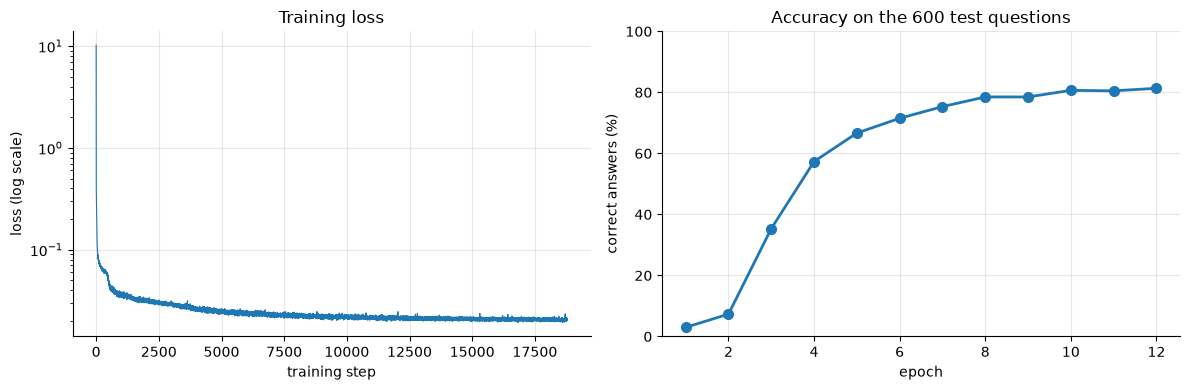

In [10]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(12, 4))
ax_loss.plot(loss_history, linewidth=0.8)
ax_loss.set_yscale("log")                      # the loss falls from about 10 to about 0.02
ax_loss.set_xlabel("training step")
ax_loss.set_ylabel("loss (log scale)")
ax_loss.set_title("Training loss")
epochs_done = range(1, len(accuracy_history) + 1)
ax_acc.plot(epochs_done, [100 * a for a in accuracy_history], linewidth=2, marker="o", markersize=7)
ax_acc.set_xlabel("epoch")
ax_acc.set_ylabel("correct answers (%)")
ax_acc.set_ylim(0, 100)
ax_acc.set_title("Accuracy on the 600 test questions")
for ax in (ax_loss, ax_acc):
    ax.grid(alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### Step 8: Begin testing

Step 7 already checked the model on the 600 test questions after every epoch, to follow the training. Step 8 tests the final result the way Task 3 asks: it loads the saved `dpo.pt` into a new model and answers the template's test set. The template code is used as it is, except `.to(device)` instead of `.cuda()`, so it also runs on a Mac or a CPU. We print the model's reply to each question.

In [11]:
# Load the fine-tuned model
ckpt_path = "../dpo/dpo.pt"
checkpoint = torch.load(ckpt_path, map_location=device)
gptconf = GPTConfig(**checkpoint['model_args'])
gpt = GPT(gptconf).to(device)
try:
    state_dict = checkpoint['model']
except:
    state_dict = checkpoint['model_state_dict']
unwanted_prefix = '_orig_mod.'
for k,v in list(state_dict.items()):
    if k.startswith(unwanted_prefix):
        state_dict[k[len(unwanted_prefix):]] = state_dict.pop(k)
gpt.load_state_dict(state_dict)
# Test
gpt.eval()
test_set = ["17+19=?", "3*17=?", "72/4=?", "72-x=34,x=?", "x*11=44,x=?", "3*17=?", "72/4=?", "72-x=34,x=?"]
with torch.no_grad():
    for prompt in test_set:
        prompt_ids = encode(prompt)
        x = torch.tensor([prompt_ids], dtype=torch.long, device=device)
        y, _ = gpt.generate(x, max_new_tokens, temperature=temperature, top_k=top_k)
        print(decode(y[0].tolist()))

17+19=? The answer is 36 because 17+19 equals 36.
3*17=? The answer is 51 because 3*17 equals 51.
72/4=? The answer is 18 because 72/4 equals 18.
72-x=34,x=? The answer is 38 because 72-34 equals to 38.
x*11=44,x=? The answer is 4 because 44/11 equals to 4.
3*17=? The answer is 51 because 3*17 equals 51.
72/4=? The answer is 18 because 72/4 equals 18.
72-x=34,x=? The answer is 38 because 72-34 equals to 38.


All 8 printed replies are correct and give the right working; for `72-x=34,x=?` the working is the reverse operation `72-34`. These 5 questions are also training questions here, since Task 1 does not leave them out, so this test mainly shows that the final model answers in the right form. The 600 test questions below are not in the training data.

#### Accuracy on the 600 test questions, by question type

Step 7 printed only the overall accuracy. Here the final model answers the 600 test questions once more, with the same sampling as above, and we count the correct answers for each question type. A reply is an exact match when the whole sentence, working included, is what we would have written as the positive for that question.

In [12]:
_, reply_of = test_accuracy()

correct_by_type = Counter()
total_by_type = Counter()
exact_matches = 0
wrong_replies = []
for question, answer, working in test_items:
    reply = reply_of[question]
    kind = question_type(question)
    total_by_type[kind] += 1
    if reply_is_correct(question, reply):
        correct_by_type[kind] += 1
    else:
        wrong_replies.append(reply)
    if reply == make_positive(question, answer, working):
        exact_matches += 1

print(f"{'question type':<14} correct")
for kind in total_by_type:
    print(f"{kind:<14} {correct_by_type[kind]:3d} / {total_by_type[kind]}")
total_correct = sum(correct_by_type.values())
print(f"{'all':<14} {total_correct:3d} / {len(test_items)} = {total_correct / len(test_items):.1%}")
print(f"Exact matches (answer and working): {exact_matches} / {len(test_items)}")
print("Some wrong replies:")
for reply in wrong_replies[:8]:
    print(" ", reply)

question type  correct
n+n=?           50 / 50
n-n=?           50 / 50
n*n=?           15 / 50
n/n=?           40 / 50
x+n=n,x=?       50 / 50
n+x=n,x=?       50 / 50
x-n=n,x=?       50 / 50
n-x=n,x=?       50 / 50
x*n=n,x=?       41 / 50
n*x=n,x=?       39 / 50
x/n=n,x=?       18 / 50
n/x=n,x=?       41 / 50
all            494 / 600 = 82.3%
Exact matches (answer and working): 494 / 600
Some wrong replies:
  24*14=? The answer is 376 because 24*14 equals 376.
  58*95=? The answer is 5490 because 58*95 equals 5490.
  25*71=? The answer is 1715 because 25*71 equals 1715.
  56*44=? The answer is 2104 because 56*44 equals 2104.
  64*46=? The answer is 2384 because 64*46 equals 2384.
  95*71=? The answer is 6645 because 95*71 equals 6645.
  74*41=? The answer is 3214 because 74*41 equals 3214.
  92*89=? The answer is 8388 because 92*89 equals 8388.


The model answers 494 of the 600 test questions correctly (82.3%), and every correct reply also has the right working (494 exact matches). How well it does depends on the operation:

| Question types | Correct |
|---|---|
| Addition and subtraction (6 types) | 300 / 300 (100%) |
| Division: `a/b=?`, and the equations `x*a=b`, `a*x=b`, `a/x=b`, whose answer is a quotient | 161 / 200 (80.5%) |
| Multiplication: `a*b=?`, and `x/a=b`, whose answer is `a*b` | 33 / 100 (33%) |

Multiplication is the weak point. The wrong products printed above are close: all 8 have the right number of digits, the right first digit and the right last digit; for example, the model writes 2104 for `56*44`, which is 2464. The last digit of a product depends only on the last digits of the two factors, and the first digit on their rough size. The middle digits need several carries, and the model has to write them in one go, most significant digit first. Lee et al. (2023) also found multiplication much harder than addition for small transformers.

The test questions are new as questions, but a related fact can be in the training data (for example `14*24=?` for `24*14=?`), so this accuracy measures how well the model answers questions it has not seen in this exact form.

## Summary

- **Task 1.** 100,202 positive-negative pairs over 12 question types with numbers from 0–100, plus 600 test questions. The positives follow the wording of the sample file; the negatives are the pretrained model's own replies, refusals such as "Sorry, I don't know.", generated with `gpt.generate` (190 minutes).
- **Task 2.** DPO with the template's loss and `compute_logprob`, AdamW with a cosine schedule, learning rate `1e-3` and 12 epochs: 114 minutes on an Apple M2 Pro, including the test after every epoch. The model learns the reply format first and the arithmetic from the third epoch on.
- **Task 3.** All 8 replies to the template's test set are correct. On the 600 test questions, which are not in the training data, the model is right 82.3% of the time: every addition and subtraction, 80.5% of the divisions and 33% of the multiplications.
- **Weak point and next step.** Multiplying two 2-digit numbers in one go is the weak point. Lee et al. (2023) found that small transformers multiply much better when the working shows intermediate steps, such as partial products. That would change the reply format given in the sample file, so we kept the sample wording.

## References

- A. Karpathy, *nanoGPT*, https://github.com/karpathy/nanoGPT. `model.py` and `configurator.py` come from this repository and are not modified.
- Course base code, https://github.com/zhouyuan888888/NanoGPT-Math. It provides the pretrained model `sft/gpt.pt`, the character codebook `sft/meta.pkl`, the sample `pos_neg_pairs.json`, and the template notebook: the code of Steps 1–4 (Step 2 with the changes listed there), `compute_logprob`, `pad_or_truncate`, `get_batches`, the skeletons of Steps 7 and 8, and the suggested loss.
- R. Rafailov, A. Sharma, E. Mitchell, S. Ermon, C. D. Manning, C. Finn, "Direct Preference Optimization: Your Language Model is Secretly a Reward Model", NeurIPS 2023, https://arxiv.org/abs/2305.18290.
- N. Lee, K. Sreenivasan, J. D. Lee, K. Lee, D. Papailiopoulos, "Teaching Arithmetic to Small Transformers", ICLR 2024, https://arxiv.org/abs/2307.03381.
- PyTorch documentation for `torch.optim.AdamW`, `torch.optim.lr_scheduler.CosineAnnealingLR` and `torch.nn.utils.clip_grad_norm_`.

Written for this assignment: the Task 1 cells, the code of Steps 5–7, the completion of Step 8 and the evaluation on the test questions, and all explanations.